# 1.2 The SI & SIS Model

We start with the **simplest possible compartmental model of an epidemic**: every individual in a population of size $N = 6 \times 10^7$ (roughly the UK population) is in one of two states:

- **$S$ (`u[1]`)** — **Susceptible** (healthy people who can catch the infection)
- **$I$ (`u[2]`)** — **Infectious** (infected people who can transmit the disease to others)

Click **⚡ Activate Live Editable Julia Cells** above to run and edit the simulations live, or read straight through with the pre-computed plots!

## Model Diagram & Equations

![SI and SIS compartmental model](../images/sis-diagram.svg)

We describe how $S$ and $I$ change over time using two ordinary differential equations (ODEs):

$$
\frac{dS}{dt} = - r \beta S I + \gamma I
$$

$$
\frac{dI}{dt} = r \beta S I - \gamma I
$$

### Reading the Equation in Plain English

- $\dfrac{dI}{dt}$ = **Rate of change of infected people over time**
- $+ r \beta S I$ = **New infections per day**: depends on how many contacts happen ($r$), the probability of transmission per contact ($\beta$), how many susceptible people exist ($S$), and how many infectious people exist ($I$).
- $- \gamma I$ = **Recoveries per day**: infectious people recover at rate $\gamma$ and return to the susceptible pool (when $\gamma = 0$, nobody recovers — that is the pure **SI** model; when $\gamma > 0$, people can be re-infected — the **SIS** model!).

:::{admonition} Class Discussion Question
:class: note
**What real-world biological or social factors affect the infection rate ($r \cdot \beta$)?**
Think separately about **contacts ($r$)** (e.g. crowded transport, lockdowns, schools) and **transmission probability ($\beta$)** (e.g. masks, handwashing, pathogen infectiousness).
:::

## Step 1: Load Julia Packages

First, we load two scientific computing packages in Julia:
- `DifferentialEquations` — solves our differential equations over time
- `Plots` — draws the epidemic curves

In [ ]:
using DifferentialEquations
using Plots
println("DifferentialEquations and Plots loaded!")

DifferentialEquations and Plots loaded!

## Step 2: Run the Baseline SI Simulation

Below is the exact SI/SIS model code. Notice that initially `gamma = 0.0` (so once someone is infected, they stay infected — a pure **SI** model).

Run the cell (or edit `r`, `beta`, `gamma` and press `Shift + Enter`) to see how the epidemic unfolds over 100 days!

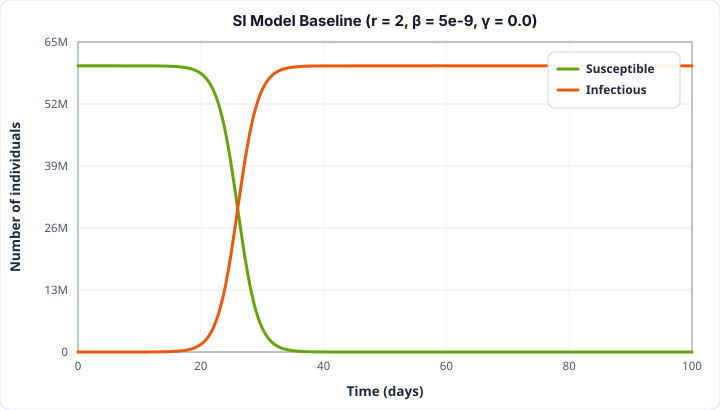

In [ ]:
# Define parameters
r     = 2       # Number of contacts per unit time
beta  = 5e-9    # Probability of disease transmission
gamma = 0.0     # Recovery rate (try 0.07 or 0.12 for an SIS model!)
N     = 6e7     # Population size (N = S + I)

# Define differential equations
function SIS!(du, u, p, t)
    r, beta, gamma = p
    du[1] = -r * beta * u[1] * u[2] + gamma * u[2]   # dS/dt
    du[2] =  r * beta * u[1] * u[2] - gamma * u[2]   # dI/dt
end

# Initial conditions, parameters, and time span
u0    = [N, 10.0]           # Start with N susceptible and 10 infectious people
p     = [r, beta, gamma]
tspan = (0.0, 100.0)        # Simulate 100 days

# Solve ODE & plot
prob = ODEProblem(SIS!, u0, tspan, p)
sol  = solve(prob)

plot(sol, lw=3, label=["Susceptible" "Infectious"],
     xlabel="Time (days)", ylabel="Number of individuals",
     title="SI/SIS Model (r=$r, β=$beta, γ=$gamma)",
     xtickfontsize=10, ytickfontsize=10, xguidefontsize=14, yguidefontsize=14, legendfontsize=10)

## Challenge 1: What Happens If the Recovery Rate Gets Higher?

In the baseline cell above, `gamma = 0.0` (no recovery), so **100% of the population eventually becomes infected**.

**Your task:** Edit the cell below to increase the recovery rate `gamma` — try `gamma = 0.07`, then `gamma = 0.12`, then `gamma = 0.7` — and observe what happens to the steady-state number of infected people!

In [ ]:
# Challenge 1 starter code — edit gamma below and press Shift + Enter!
r     = 2
beta  = 5e-9
gamma = 0.0     # <-- Try changing this to 0.07, 0.12, or 0.7!
N     = 6e7

u0    = [N, 10.0]
p     = [r, beta, gamma]
tspan = (0.0, 100.0)

prob = ODEProblem(SIS!, u0, tspan, p)
sol  = solve(prob)

plot(sol, lw=3, label=["Susceptible" "Infectious"],
     xlabel="Time (days)", ylabel="Number of individuals",
     title="SIS Challenge 1 (γ = $gamma)",
     xtickfontsize=10, ytickfontsize=10, xguidefontsize=14, yguidefontsize=14, legendfontsize=10)

````{admonition} 💡 Hint — Challenge 1
:class: tip, dropdown

You only need to change the single line `gamma = 0.0`!
Notice the infection inflow per infected person at the start is $r \cdot \beta \cdot N = 2 \times 5 \times 10^{-9} \times 6 \times 10^7 = 0.6\text{ day}^{-1}$.
Compare what happens when `gamma` is **below** `0.6` (e.g. `0.12` or `0.3`) versus **above** `0.6` (e.g. `0.7`)!
````

````{admonition} ✅ Reveal Solution — Challenge 1
:class: note, dropdown

When `gamma > 0`, the model becomes an **SIS** model:
- For `gamma = 0.12` (still below $r \beta N = 0.6$), the epidemic settles at a lower **endemic equilibrium** where new infections exactly balance recoveries ($S^* = \frac{\gamma}{r\beta} = 1.2 \times 10^7$, $I^* = N - S^* = 4.8 \times 10^7$).
- If `gamma` exceeds $r \beta N = 0.6$ (for example `gamma = 0.7`), people recover faster than they transmit and the infection **dies out completely**!

```julia
r     = 2
beta  = 5e-9
gamma = 0.12    # Try 0.3 or 0.7 as well!
N     = 6e7

u0    = [N, 10.0]
p     = [r, beta, gamma]
tspan = (0.0, 100.0)

prob = ODEProblem(SIS!, u0, tspan, p)
sol  = solve(prob)

plot(sol, lw=3, label=["Susceptible" "Infectious"],
     xlabel="Time (days)", ylabel="Number of individuals",
     title="SIS Solution (γ = $gamma)",
     xtickfontsize=10, ytickfontsize=10, xguidefontsize=14, yguidefontsize=14, legendfontsize=10)
```
````

## Challenge 2: What Happens If the Probability of Transmission Changes?

Now keep recovery at `gamma = 0.12` and explore what happens when the transmission probability `beta` (or the contact rate `r`) is reduced—for example by hygiene measures, masks, or social distancing.

**Your task:** Edit `beta` (or `r`) in the cell below and re-run to see how it changes both the **speed** of the outbreak and the **final number of infected people**.

In [ ]:
# Challenge 2 starter code — edit beta or r below and press Shift + Enter!
r     = 2       # <-- Try reducing contacts (e.g. r = 1)
beta  = 5e-9    # <-- Or reducing transmission probability (e.g. beta = 2.5e-9 or 1e-9)
gamma = 0.12
N     = 6e7

u0    = [N, 10.0]
p     = [r, beta, gamma]
tspan = (0.0, 100.0)

prob = ODEProblem(SIS!, u0, tspan, p)
sol  = solve(prob)

plot(sol, lw=3, label=["Susceptible" "Infectious"],
     xlabel="Time (days)", ylabel="Number of individuals",
     title="SIS Challenge 2 (r=$r, β=$beta, γ=$gamma)",
     xtickfontsize=10, ytickfontsize=10, xguidefontsize=14, yguidefontsize=14, legendfontsize=10)

````{admonition} 💡 Hint — Challenge 2
:class: tip, dropdown

Try halving `beta` from `5e-9` to `2.5e-9`, and then try lowering it further to `1e-9`.
Look at how long it takes the orange **Infectious** curve to rise—and how high it climbs!
````

````{admonition} ✅ Reveal Solution — Challenge 2
:class: note, dropdown

Lowering `beta` (or `r`) **delays the outbreak** AND **reduces the equilibrium number of infected people**. If $r \cdot \beta \cdot N < \gamma$ (for example `beta = 1e-9` with `r = 2`, giving $r \beta N = 0.12 = \gamma$), the outbreak cannot take off at all!

```julia
r     = 2
beta  = 2.5e-9  # Halved transmission probability
gamma = 0.12
N     = 6e7

u0    = [N, 10.0]
p     = [r, beta, gamma]
tspan = (0.0, 100.0)

prob = ODEProblem(SIS!, u0, tspan, p)
sol  = solve(prob)

plot(sol, lw=3, label=["Susceptible" "Infectious"],
     xlabel="Time (days)", ylabel="Number of individuals",
     title="SIS Solution (r=$r, β=$beta, γ=$gamma)",
     xtickfontsize=10, ytickfontsize=10, xguidefontsize=14, yguidefontsize=14, legendfontsize=10)
```
````

---

**Next:** What if recovering from an infection grants **immunity** (at least temporarily)? Move on to [**1.3 The SIR & SIRS Model**](03-sir-sirs-model.ipynb).